# Praktikum 1 - Exact NN dan Annoy

**Nama:** Agus

**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/praktikum-1)

## Langkah 0 - Persiapan Lingkungan

In [1]:
import sys
import numpy as np
np.random.seed(42)
print("Kernel:", sys.executable)

import faiss
faiss.omp_set_num_threads(4)


Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


## Langkah 1 - Import Library

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex


## Langkah 2 - Dataset 2D

In [3]:
# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]


## Langkah 3 - Exact NN (brute force)

In [4]:
# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")


Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 0.2 ms


## Langkah 4 - Annoy NN (3 tree)

In [5]:
# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")



Annoy NN index: [219, 898, 593]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.2793154441691197)]
Waktu Annoy: 0.0212 ms


## Langkah 5 - Visualisasi hasil

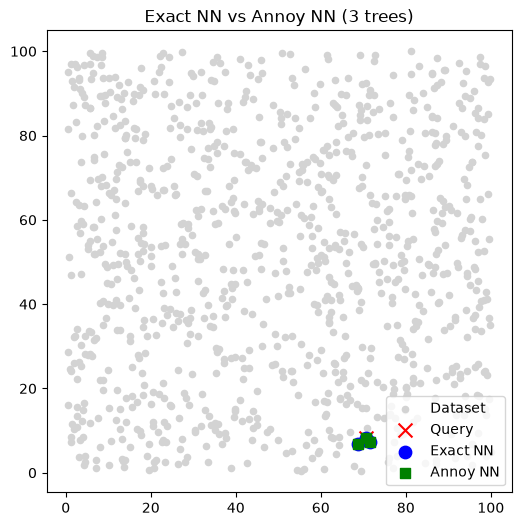

In [6]:
# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()


## Percobaan Tambahan - Tabel Euclidean dan Angular

Dataset dan query yang sama digunakan untuk kedua metrik pada ukuran yang sama. Exact Angular dihitung dari akar 2(1-cosine), sesuai metrik Annoy. Build index dicatat terpisah dari waktu satu query. Waktu dapat berubah antarrun.

In [7]:
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from annoy import AnnoyIndex
import faiss
import hnswlib


In [8]:
def coba_annoy(n, trees, metric, dim=2, k=3):
    rng = np.random.RandomState(42)
    data = rng.rand(n, dim).astype(np.float32)
    query = data[rng.randint(n)] if dim == 2 else rng.rand(dim).astype(np.float32)
    start = time.perf_counter()
    if metric == 'euclidean':
        distances = np.linalg.norm(data - query, axis=1)
    else:
        normalized = data / np.linalg.norm(data, axis=1, keepdims=True)
        q = query / np.linalg.norm(query)
        similarity = normalized @ q
        distances = np.sqrt(np.clip(2 * (1 - similarity), 0, 4))
    exact_ids = np.argsort(distances)[:k]
    exact_ms = (time.perf_counter() - start) * 1000
    start = time.perf_counter()
    index = AnnoyIndex(dim, metric)
    index.set_seed(42)
    for i, vec in enumerate(data):
        index.add_item(i, vec)
    index.build(trees)
    build_s = time.perf_counter() - start
    start = time.perf_counter()
    ids = index.get_nns_by_vector(query, k)
    ann_ms = (time.perf_counter() - start) * 1000
    result = {'Distance Metrics': metric, 'Tree': trees, 'Jumlah data': n, 'Dimensi': dim,
        'Index ENN': exact_ids.tolist(), 'Index ANN': ids,
        'Waktu ENN (ms)': exact_ms, 'Waktu ANN (ms)': ann_ms,
        'Build ANN (s)': build_s, 'Recall@k': len(set(exact_ids) & set(ids)) / k}
    del index, data
    gc.collect()
    return result

results_2d = [coba_annoy(n, trees, metric)
    for metric in ['euclidean', 'angular']
    for n, trees in [(1000, 3), (1000, 8), (100_000, 3)]]
display(pd.DataFrame(results_2d).round(6))


,Distance Metrics,Tree,Jumlah data,Dimensi,Index ENN,Index ANN,Waktu ENN (ms),Waktu ANN (ms),Build ANN (s),Recall@k
0,euclidean,3,1000,2,"[219, 898, 593]","[219, 898, 593]",0.169208,0.004375,0.001426,1.000000
1,euclidean,8,1000,2,"[219, 898, 593]","[219, 898, 593]",0.069417,0.008500,0.004059,1.000000
2,euclidean,3,100000,2,"[64040, 64186, 88792]","[64040, 64186, 88792]",6.325875,0.018917,0.124169,1.000000
3,angular,3,1000,2,"[219, 429, 540]","[219, 429, 540]",0.089625,0.006792,0.001941,1.000000
4,angular,8,1000,2,"[219, 429, 540]","[219, 429, 540]",0.083625,0.009792,0.004329,1.000000
5,angular,3,100000,2,"[74022, 44489, 1310]","[41684, 5576, 74022]",6.790334,0.015125,0.313253,0.333333


## Simulasi Track 20 Fitur

Teks dan tabel modul meminta **1 juta track**, sedangkan contoh kode menulis 50 juta. Percobaan ini mengikuti ukuran 1 juta pada tabel, dengan 8 tree dan 5 tetangga. Ini data sintetis, terpisah dari dataset nyata Praktikum 6.

In [9]:
results_tracks = [coba_annoy(1_000_000, 8, metric, dim=20, k=5)
                  for metric in ['euclidean', 'angular']]
display(pd.DataFrame(results_tracks).round(6))


,Distance Metrics,Tree,Jumlah data,Dimensi,Index ENN,Index ANN,Waktu ENN (ms),Waktu ANN (ms),Build ANN (s),Recall@k
0,euclidean,8,1000000,20,"[229350, 553886, 763448, 256344, 308000]","[975035, 852569, 941513, 155696, 172822]",96.549833,0.032375,1.709813,0.0
1,angular,8,1000000,20,"[308000, 376840, 229350, 763448, 553886]","[308000, 400141, 531164, 547819, 550146]",95.741666,0.041458,1.857129,0.2


## Jawaban

Build index tidak dimasukkan dalam waktu query karena index dapat dibangun sekali lalu digunakan untuk banyak pencarian. Biayanya tetap perlu dilaporkan: untuk sedikit query, build dapat lebih mahal daripada keuntungan query ANN. Tree lebih banyak dapat meningkatkan recall, ukuran index, dan waktu build. Tidak ada jaminan ANN selalu lebih cepat atau menemukan seluruh tetangga exact.

Pada Angular 2D dengan banyak baris, beberapa jarak sangat kecil dapat
membulat ke nol dalam float32. ID berbeda pada jarak seri dapat menurunkan
recall berbasis ID meskipun kedekatan geometrisnya hampir sama.